## model v2 dataset

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

GEN_PATH = '../../01_data/2_cleaned/generation/hourly_solar_wind_generation_2020_2025.parquet'
LOAD_PATH = '../../01_data/2_cleaned/load/total_load_20201231_20260526.csv'
CAPACITY_PATH = '../../01_data/2_cleaned/generation/ERCOT nonRE capacity 2020-2025.csv'
NG_PATH = '../../01_data/3_analysis/ng_price/ng_prices_monthly.csv'
TEMP_PATH = '../../01_data/2_cleaned/weather/Texas_hourly_temp_2021_2025.csv'
PEAK_HR_PATH = '../../01_data/2_cleaned/peak hours/peak_hour_2021_2025.csv'

OUTAGE_PATH = '../../01_data/2_cleaned/outage/archive_1h_ahead_outage_20210101_2026_0924.parquet'
AGG_PRICE_PATH = '../../01_data/3_analysis/price incentive metrics/rtm_adder_aggregated_20210101_20251203.csv'

OUT_DIR = Path('../../01_data/4_model')

In [2]:
df_gen = pd.read_parquet(GEN_PATH)
df_load = pd.read_csv(LOAD_PATH)
df_capacity = pd.read_csv(CAPACITY_PATH)
df_total_cap = df_capacity.filter(['year', 'total_mw'])
df_total_cap = df_total_cap.rename(columns={'total_mw': 'non_re_capacity'})
df_total_cap['non_re_capacity'] = df_total_cap['non_re_capacity'].astype(int)

df_price = pd.read_csv(AGG_PRICE_PATH)

df_ng = pd.read_csv(NG_PATH)
df_ng['date'] = pd.to_datetime(df_ng['date'])
df_ng['month'] = df_ng['date'].dt.month
df_ng['year'] = df_ng['date'].dt.year

df_temp = pd.read_csv(TEMP_PATH)

df_peak = pd.read_csv(PEAK_HR_PATH)

df_outage = pd.read_parquet(OUTAGE_PATH)
df_outage['datetime'] = pd.to_datetime(df_outage['datetime'])

In [3]:
import duckdb

# price without adders
con = duckdb.connect()
df_base_price = con.execute("""
   WITH Merged AS (
      SELECT
         g.datetime
         ,MONTH(g.datetime) AS month
         ,price_wo_adders
         ,renewable_gen
         ,total_load
         ,non_re_capacity
         ,henry_hub AS ng_price_monthly
         ,tx_temp
         ,peak_hour
         ,totalResourceMW AS outage
      
      FROM df_gen g
         JOIN df_load l ON g.datetime = l.datetime
         LEFT JOIN df_total_cap c ON YEAR(g.datetime) = c.year
         JOIN df_price p ON g.datetime = p.datetime
         LEFT JOIN df_ng n ON YEAR(n.date) = YEAR(g.datetime)
                           AND MONTH(n.date) = MONTH(g.datetime)
         LEFT JOIN df_temp t ON t.datetime = g.datetime
         LEFT JOIN df_peak ON g.datetime = df_peak.datetime
         JOIN df_outage o ON o.datetime = g.datetime                
      )
   
   SELECT
         datetime
         ,YEAR(datetime) AS year
         ,HOUR(datetime) AS time_of_day
         ,peak_hour
         ,CASE WHEN month IN (12, 1, 2)  THEN 'winter'
               WHEN month IN (3, 4, 5)   THEN 'spring'
               WHEN month IN (6, 7, 8)   THEN 'summer'
               WHEN month IN (9, 10, 11) THEN 'fall'
          END AS season
         ,price_wo_adders
         ,total_load
         ,total_load / MAX(total_load) OVER (PARTITION BY year) AS perc_load
         ,(total_load - renewable_gen)/(non_re_capacity - outage) AS spare_capacity
         ,ng_price_monthly
         ,ABS(tx_temp - 65) AS degree_days
         ,(CASE WHEN (tx_temp - 65) > 0 THEN TRUE
               WHEN (tx_temp - 65) < 0 THEN FALSE
               ELSE NULL END)
               as heating_dd
   FROM Merged
   ORDER BY datetime;
""").fetchdf()

df_base_price = df_base_price.dropna()
df_base_price

,datetime,year,time_of_day,peak_hour,season,price_wo_adders,total_load,perc_load,spare_capacity,ng_price_monthly,degree_days,heating_dd
0,2021-01-01 01:00:00,2021,1,False,winter,18.173500,43713.80,0.594948,0.507010,2.712632,29.698555,False
1,2021-01-01 02:00:00,2021,2,False,winter,20.960833,43314.37,0.589511,0.494391,2.712632,30.076485,False
2,2021-01-01 03:00:00,2021,3,False,winter,20.779667,43048.35,0.585891,0.491019,2.712632,30.348450,False
3,2021-01-01 04:00:00,2021,4,False,winter,16.416667,43073.65,0.586235,0.508057,2.712632,31.037514,False
4,2021-01-01 05:00:00,2021,5,False,winter,18.075333,43448.89,0.591342,0.531662,2.712632,32.820100,False
...,...,...,...,...,...,...,...,...,...,...,...,...
43144,2025-12-03 19:00:00,2025,19,True,winter,37.510333,54497.98,0.649729,0.840561,4.263810,9.542927,False
43145,2025-12-03 20:00:00,2025,20,True,winter,40.374667,54169.25,0.645810,0.784120,4.263810,10.943300,False
43146,2025-12-03 21:00:00,2025,21,True,winter,38.039500,53803.77,0.641453,0.739089,4.263810,12.875572,False
43147,2025-12-03 22:00:00,2025,22,True,winter,34.266667,52867.06,0.630285,0.695477,4.263810,13.614403,False


In [4]:
# adders only


In [5]:
# add 1 / reserve_margin

### data inspection and export

In [6]:
df = df_base_price.copy()

summary = pd.DataFrame({
    "col_name": df.columns,
    "dtype": df.dtypes,
    "n_missing": [df[col].isna().sum() for col in df.columns],
    "missing_rate": [round(df[col].isna().mean()*100, 2) for col in df.columns],
    "is_unique": df.columns.duplicated(),
    "n_unique": [df[col].nunique() for col in df.columns],
    "sample_values": [list(df[col].unique()[0:3]) for col in df.columns]
})
summary

,col_name,dtype,n_missing,missing_rate,is_unique,n_unique,sample_values
datetime,datetime,datetime64[us],0,0.0,False,43138,"[2021-01-01 01:00:00, 2021-01-01 02:00:00, 202..."
year,year,int64,0,0.0,False,5,"[2021, 2022, 2023]"
time_of_day,time_of_day,int64,0,0.0,False,24,"[1, 2, 3]"
peak_hour,peak_hour,bool,0,0.0,False,2,"[False, True]"
season,season,str,0,0.0,False,4,"[winter, spring, summer]"
price_wo_adders,price_wo_adders,float64,0,0.0,False,40745,"[18.1735, 20.96083333333333, 20.779666666666667]"
total_load,total_load,float64,0,0.0,False,42875,"[43713.8, 43314.37, 43048.35]"
perc_load,perc_load,float64,0,0.0,False,43062,"[0.5949475366127686, 0.5895112694717458, 0.585..."
spare_capacity,spare_capacity,float64,0,0.0,False,43147,"[0.5070100279691657, 0.49439149023148077, 0.49..."
ng_price_monthly,ng_price_monthly,float64,0,0.0,False,60,"[2.7126315789473683, 5.353684210526316, 2.6182..."


In [7]:
df_base_price.to_csv(OUT_DIR / 'base_price_model_dataset_20210101_20251203.csv', index=False)

### correlation plots

In [8]:
print('overall correlation:')

df_cor = df.filter(['price_wo_adders', 'degree_days', 'spare_capacity', 'total_load'])
corr_matrix = df_cor.corr(method='pearson')
pd.DataFrame(corr_matrix)

overall correlation:


,price_wo_adders,degree_days,spare_capacity,total_load
price_wo_adders,1.000000,0.220517,0.226670,0.104258
degree_days,0.220517,1.000000,0.476247,0.658731
spare_capacity,0.226670,0.476247,1.000000,0.641895
total_load,0.104258,0.658731,0.641895,1.000000


<Axes: >

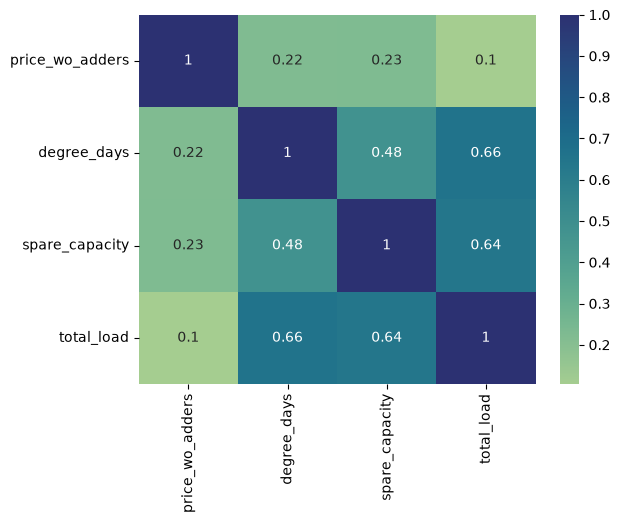

In [9]:
import seaborn as sns
sns.heatmap(corr_matrix, annot=True, cmap='crest')

In [10]:
# monthly including ng price
df_monthly = df.copy()
df_monthly['month'] = df_monthly['datetime'].dt.month
df_monthly = df_monthly.filter(['year', 'month', 'price_wo_adders', 'degree_days', 'spare_capacity', 'total_load', 'ng_price_monthly'])
df_monthly = df_monthly.groupby(['year', 'month']).mean().reset_index()

df_monthly = df_monthly.filter(['price_wo_adders', 'degree_days', 'spare_capacity', 'total_load', 'ng_price_monthly'])
df_monthly_cor = df_monthly.corr(method='pearson')
df_monthly_cor

,price_wo_adders,degree_days,spare_capacity,total_load,ng_price_monthly
price_wo_adders,1.000000,0.347541,0.244692,0.033873,0.250466
degree_days,0.347541,1.000000,0.444716,0.637953,0.196126
spare_capacity,0.244692,0.444716,1.000000,0.775536,0.025799
total_load,0.033873,0.637953,0.775536,1.000000,-0.040335
ng_price_monthly,0.250466,0.196126,0.025799,-0.040335,1.000000


<Axes: >

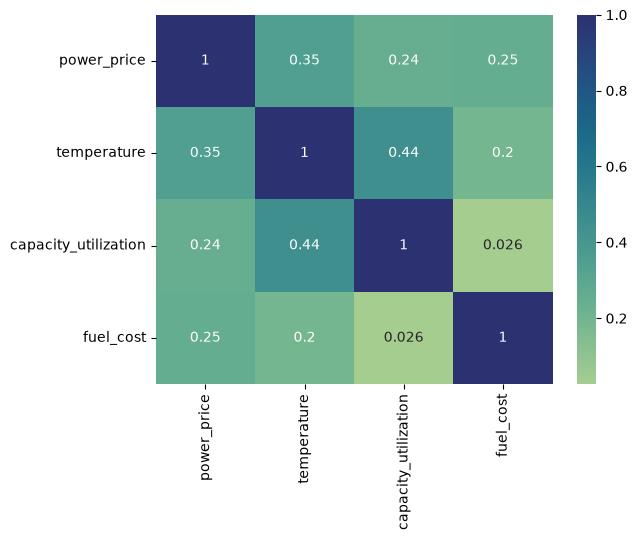

In [11]:
df_present = df_monthly.filter(['price_wo_adders', 'degree_days', 'spare_capacity', 'ng_price_monthly'])

df_present = df_present.rename(columns={
    'price_wo_adders': 'power_price',
    'degree_days': 'temperature',
    'spare_capacity': 'capacity_utilization',
    'ng_price_monthly': 'fuel_cost'
})
df_present_cor = df_present.corr(method='pearson')
sns.heatmap(df_present_cor, annot=True, cmap='crest')

Heatmap of correlation among monthly value
    price_wo_adders  degree_days  spare_capacity    total_load  \
0         20.695799    17.257911        0.536858  41350.153015   
1        609.490014    21.259376        0.692831  43133.009628   
2         18.311540     8.295062        0.553670  36647.026051   
3         43.813452     7.842168        0.701436  38986.632306   
4         23.396369     8.527565        0.587131  42731.407581   
5         35.973493    16.020727        0.681041  51843.253222   
6         34.565292    16.479088        0.716079  53158.821788   
7         34.922572    17.412175        0.707765  55601.386438   
8         41.723448    14.645613        0.652347  50790.312472   
9         45.223124     9.060249        0.634947  43917.299691   
10        39.709423     9.740411        0.550639  38866.434465   
11        25.668337     8.984206        0.507624  40598.769409   
12        28.941845    18.784340        0.554389  44895.912137   
13        27.041909    19.520442 

<Axes: >

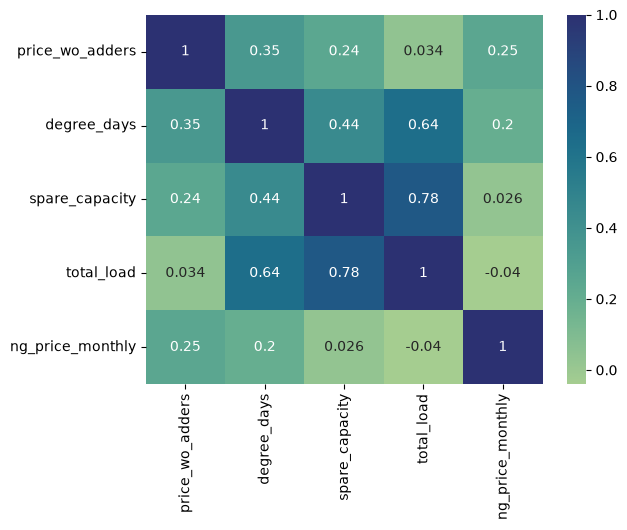

In [12]:
print('Heatmap of correlation among monthly value')

# modified version for poster
df_monthly.rename({
    'price_wo_adders': 'power_price',
    'degree_days': 'temperature',
    'spare_capacity': 'capacity_utilization',
    'total_load': 'load',
    'ng_price_monthly': 'fuel_cost'
})
print(df_monthly)
df_presented_cor = df_monthly.corr(method='pearson')
sns.heatmap(df_presented_cor, annot=True, cmap='crest')

In [13]:
for year in [2021, 2022, 2023, 2024, 2025]:
    df_year = df[df['year'] == year]
    df_cor = df_year.filter(['price_wo_adders', 'spare_capacity', 'ng_price_monthly', 'degree_days'])
    corr_matrix = df_cor.corr(method='pearson')
    print(f'\n===== {year} ======')
    print(corr_matrix)


===== 2021 ======
                  price_wo_adders  spare_capacity  ng_price_monthly  \
price_wo_adders          1.000000        0.303723          0.140894   
spare_capacity           0.303723        1.000000          0.082300   
ng_price_monthly         0.140894        0.082300          1.000000   
degree_days              0.366407        0.548658          0.119241   

                  degree_days  
price_wo_adders      0.366407  
spare_capacity       0.548658  
ng_price_monthly     0.119241  
degree_days          1.000000  

===== 2022 ======
                  price_wo_adders  spare_capacity  ng_price_monthly  \
price_wo_adders          1.000000        0.300085          0.149718   
spare_capacity           0.300085        1.000000          0.341181   
ng_price_monthly         0.149718        0.341181          1.000000   
degree_days              0.195942        0.579980          0.073905   

                  degree_days  
price_wo_adders      0.195942  
spare_capacity       0.579


===== 2023 ======
                  price_wo_adders  spare_capacity  ng_price_monthly  \
price_wo_adders          1.000000        0.270723          0.002857   
spare_capacity           0.270723        1.000000         -0.125813   
ng_price_monthly         0.002857       -0.125813          1.000000   
degree_days              0.236586        0.535894          0.058818   

                  degree_days  
price_wo_adders      0.236586  
spare_capacity       0.535894  
ng_price_monthly     0.058818  
degree_days          1.000000  

===== 2024 ======
                  price_wo_adders  spare_capacity  ng_price_monthly  \
price_wo_adders          1.000000        0.309483          0.038646   
spare_capacity           0.309483        1.000000          0.082253   
ng_price_monthly         0.038646        0.082253          1.000000   
degree_days              0.142802        0.403553          0.260961   

                  degree_days  
price_wo_adders      0.142802  
spare_capacity       0.403